# Import needed modules

In [ ]:
!pip install tensorflow


In [ ]:
# import system libs
import os
import time
import shutil
import itertools

# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt

# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.models import Model, load_model, Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras import regularizers
from tensorflow.keras.metrics import categorical_crossentropy

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print ('modules loaded')

modules loaded


# Create needed functions

#### Function to Create Data Frame from Dataset

In [ ]:
# Generate data paths with lables
def define_paths(dir):
    filepaths = []
    labels = []

    folds = os.listdir(dir)
    for fold in folds:
        foldpath = os.path.join(dir, fold)
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            filepaths.append(fpath)
            labels.append(fold)

    return filepaths, labels


# Conctainate data pathes with lables into one dataframe ( to later be fitted into the model )
def define_df(files, classes):
    Fseries = pd.Series(files, name= 'filepaths')
    Lseries = pd.Series(classes, name='labels')
    return pd.concat([Fseries, Lseries], axis= 1)


# Split data into train, validation, and test
def split_data(tr_dir, ts_dir):
    # train and # validation dataframe
    files, classes = define_paths(tr_dir)
    df = define_df(files, classes)
    strat = df['labels']
    train_df, valid_df = train_test_split(df,  train_size= 0.8, shuffle= True, random_state= 123, stratify= strat)

    # test dataframe
    files, classes = define_paths(ts_dir)
    test_df = define_df(files, classes)

    return train_df, valid_df, test_df

#### Function to generate images from dataframe

In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
def create_model_data (train_df, valid_df, test_df, batch_size):

    ''' This function takes train, validation, and test dataframe and fit them into image data generator, because model takes
         data from image data generator.
         Image data generator converts images into tensors. '''


    # define model parameters
    img_size = (224, 224)
    channels = 3 # either BGR or Grayscale
    color = 'rgb'
    img_shape = (img_size[0], img_size[1], channels)

    # Recommended : use custom function for test data batch size, else we can use normal batch size.
    ts_length = len(test_df)
    test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
    test_steps = ts_length // test_batch_size

    # This function which will be used in image data generator for data augmentation, it just take the image and return it again.
    # def scalar(img):
    #     return img

    # NEW — use EfficientNet-specific preprocessing

    tr_gen = ImageDataGenerator(preprocessing_function=preprocess_input, horizontal_flip=True)
    ts_gen = ImageDataGenerator(preprocessing_function=preprocess_input)


    train_gen = tr_gen.flow_from_dataframe( train_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                        color_mode= color, shuffle= True, batch_size= batch_size)

    valid_gen = ts_gen.flow_from_dataframe( valid_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                        color_mode= color, shuffle= True, batch_size= batch_size)

    # Note: we will use custom test_batch_size, and make shuffle= false
    test_gen = ts_gen.flow_from_dataframe( test_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                        color_mode= color, shuffle= False, batch_size= test_batch_size)


    return train_gen, valid_gen, test_gen

#### Function to display data sample

In [ ]:
def show_images(gen):

    # return classes , images to be displayed
    g_dict = gen.class_indices        # defines dictionary {'class': index}
    classes = list(g_dict.keys())     # defines list of dictionary's kays (classes), classes names : string
    images, labels = next(gen)        # get a batch size samples from the generator


    # calculate number of dispalyed samples
    length = len(labels)        # length of batch size
    sample = min(length, 25)    # check if sample less than 25 images

    plt.figure(figsize= (20, 20))

    for i in range(sample):
        plt.subplot(5, 5, i + 1)
        image = images[i] / 255       # scales data to range (0 - 255)
        plt.imshow(image)

        # note
        index = np.argmax(labels[i])  # get image index

        class_name = classes[index]   # get class of image

        plt.title(class_name, color= 'blue', fontsize= 12)
        plt.axis('off')
    plt.show()

#### **Callbacks**
<br>
Callbacks : Helpful functions to help optimize model training  <br>
Examples: stop model training after specfic time, stop training if no improve in accuracy and so on.

In [ ]:
class MyCallback(keras.callbacks.Callback):
    def __init__(self, monitor='val_loss', min_delta=0.001, warmup=3,
                 patience=3, stop_patience=7, factor=0.5, epochs=20, ask_epoch=5):
        super(MyCallback, self).__init__()
        self.monitor = monitor
        self.min_delta = min_delta
        self.warmup = warmup
        self.patience = patience
        self.stop_patience = stop_patience
        self.factor = factor
        self.epochs = epochs
        self.ask_epoch = ask_epoch
        self.wait = 0
        self.stop_wait = 0
        self.best_val = np.inf
        self.best_weights = None
        self.start_time = time.time()
        self.lr = None

    def on_train_begin(self, logs=None):
        lr_attr = self.model.optimizer.learning_rate
        self.lr = float(tf.keras.backend.get_value(lr_attr)) if hasattr(lr_attr, 'numpy') else float(lr_attr)
        print(f"{'Epoch':<8}{'Loss':<10}{'Accuracy':<10}{'V_loss':<10}{'V_acc':<10}{'LR':<10}{'Next LR':<10}{'% Improv':<10}{'Duration':<10}")

    def on_epoch_end(self, epoch, logs=None):
        val = logs.get(self.monitor)
        loss = logs.get("loss")
        acc = logs.get("accuracy")
        val_loss = logs.get("val_loss")
        val_acc = logs.get("val_accuracy")

        duration = time.time() - self.start_time
        self.start_time = time.time()

        # Save fallback weights
        if epoch == 0 and self.best_weights is None:
            self.best_weights = self.model.get_weights()

        improvement = (self.best_val - val) / self.best_val * 100 if self.best_val != np.inf else 0

        # Skip LR logic during warmup
        if epoch < self.warmup:
            print(f"{epoch+1:>2}/{self.epochs:<5}{loss:<10.3f}{acc*100:<10.3f}{val_loss:<10.3f}{val_acc*100:<10.3f}{self.lr:<10.6f}{self.lr:<10.6f}{improvement:<10.2f}{duration:<10.2f}")
            return

        if val + self.min_delta < self.best_val:
            self.best_val = val
            self.wait = 0
            self.stop_wait = 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
            self.stop_wait += 1
            if self.wait >= self.patience:
                lr_attr = self.model.optimizer.learning_rate
                old_lr = float(tf.keras.backend.get_value(lr_attr)) if hasattr(lr_attr, 'numpy') else float(lr_attr)
                new_lr = old_lr * self.factor

                if hasattr(lr_attr, 'assign'):
                    lr_attr.assign(new_lr)
                else:
                    self.model.optimizer.learning_rate = new_lr

                print(f"\nLR reduced from {old_lr:.6f} to {new_lr:.6f}")
                self.wait = 0

            if self.stop_wait >= self.stop_patience:
                print(f"\nTraining stopped at epoch {epoch+1} due to no improvement.")
                self.model.stop_training = True
                if self.best_weights is not None:
                    self.model.set_weights(self.best_weights)
                else:
                    print("Warning: No best weights recorded.")

        lr_attr = self.model.optimizer.learning_rate
        next_lr = float(tf.keras.backend.get_value(lr_attr)) if hasattr(lr_attr, 'numpy') else float(lr_attr)
        print(f"{epoch+1:>2}/{self.epochs:<5}{loss:<10.3f}{acc*100:<10.3f}{val_loss:<10.3f}{val_acc*100:<10.3f}{self.lr:<10.6f}{next_lr:<10.6f}{improvement:<10.2f}{duration:<10.2f}")

        self.lr = next_lr

        if (epoch + 1) == self.ask_epoch:
            response = input("\nDo you want model to ask you to halt training [y/n]?\n")
            if response.lower().startswith('y'):
                print("Training halted by user.")
                self.model.stop_training = True


#### Function to plot history of training

In [ ]:
def plot_training(hist):
    tr_acc = hist.history['accuracy']
    tr_loss = hist.history['loss']
    val_acc = hist.history['val_accuracy']
    val_loss = hist.history['val_loss']
    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]
    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]

    plt.figure(figsize= (20, 8))
    plt.style.use('fivethirtyeight')
    Epochs = [i+1 for i in range(len(tr_acc))]
    loss_label = f'best epoch= {str(index_loss + 1)}'
    acc_label = f'best epoch= {str(index_acc + 1)}'
    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
    plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
    plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
    plt.title('Proposed Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
    plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
    plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
    plt.title('Proposed Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.tight_layout
    plt.show()


#### Function to create Confusion Matrix

In [ ]:
def plot_confusion_matrix(cm, classes, normalize= False, title= 'Confusion Matrix - Proposed Model', cmap= plt.cm.Blues):
	plt.figure(figsize= (10, 10))
	plt.imshow(cm, interpolation= 'nearest', cmap= cmap)
	plt.title(title)
	plt.colorbar()
	tick_marks = np.arange(len(classes))
	plt.xticks(tick_marks, classes, rotation= 45)
	plt.yticks(tick_marks, classes)
	if normalize:
		cm = cm.astype('float') / cm.sum(axis= 1)[:, np.newaxis]
		print('Normalized Confusion Matrix')
	else:
		print('Confusion Matrix, Without Normalization')
	print(cm)
	thresh = cm.max() / 2.
	for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
		plt.text(j, i, cm[i, j], horizontalalignment= 'center', color= 'white' if cm[i, j] > thresh else 'black')
	plt.tight_layout()
	plt.ylabel('True Label')
	plt.xlabel('Predicted Label')

# Model Structure

#### Start Reading Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Found 1048 validated image filenames belonging to 4 classes.
Found 263 validated image filenames belonging to 4 classes.
Found 1311 validated image filenames belonging to 4 classes.


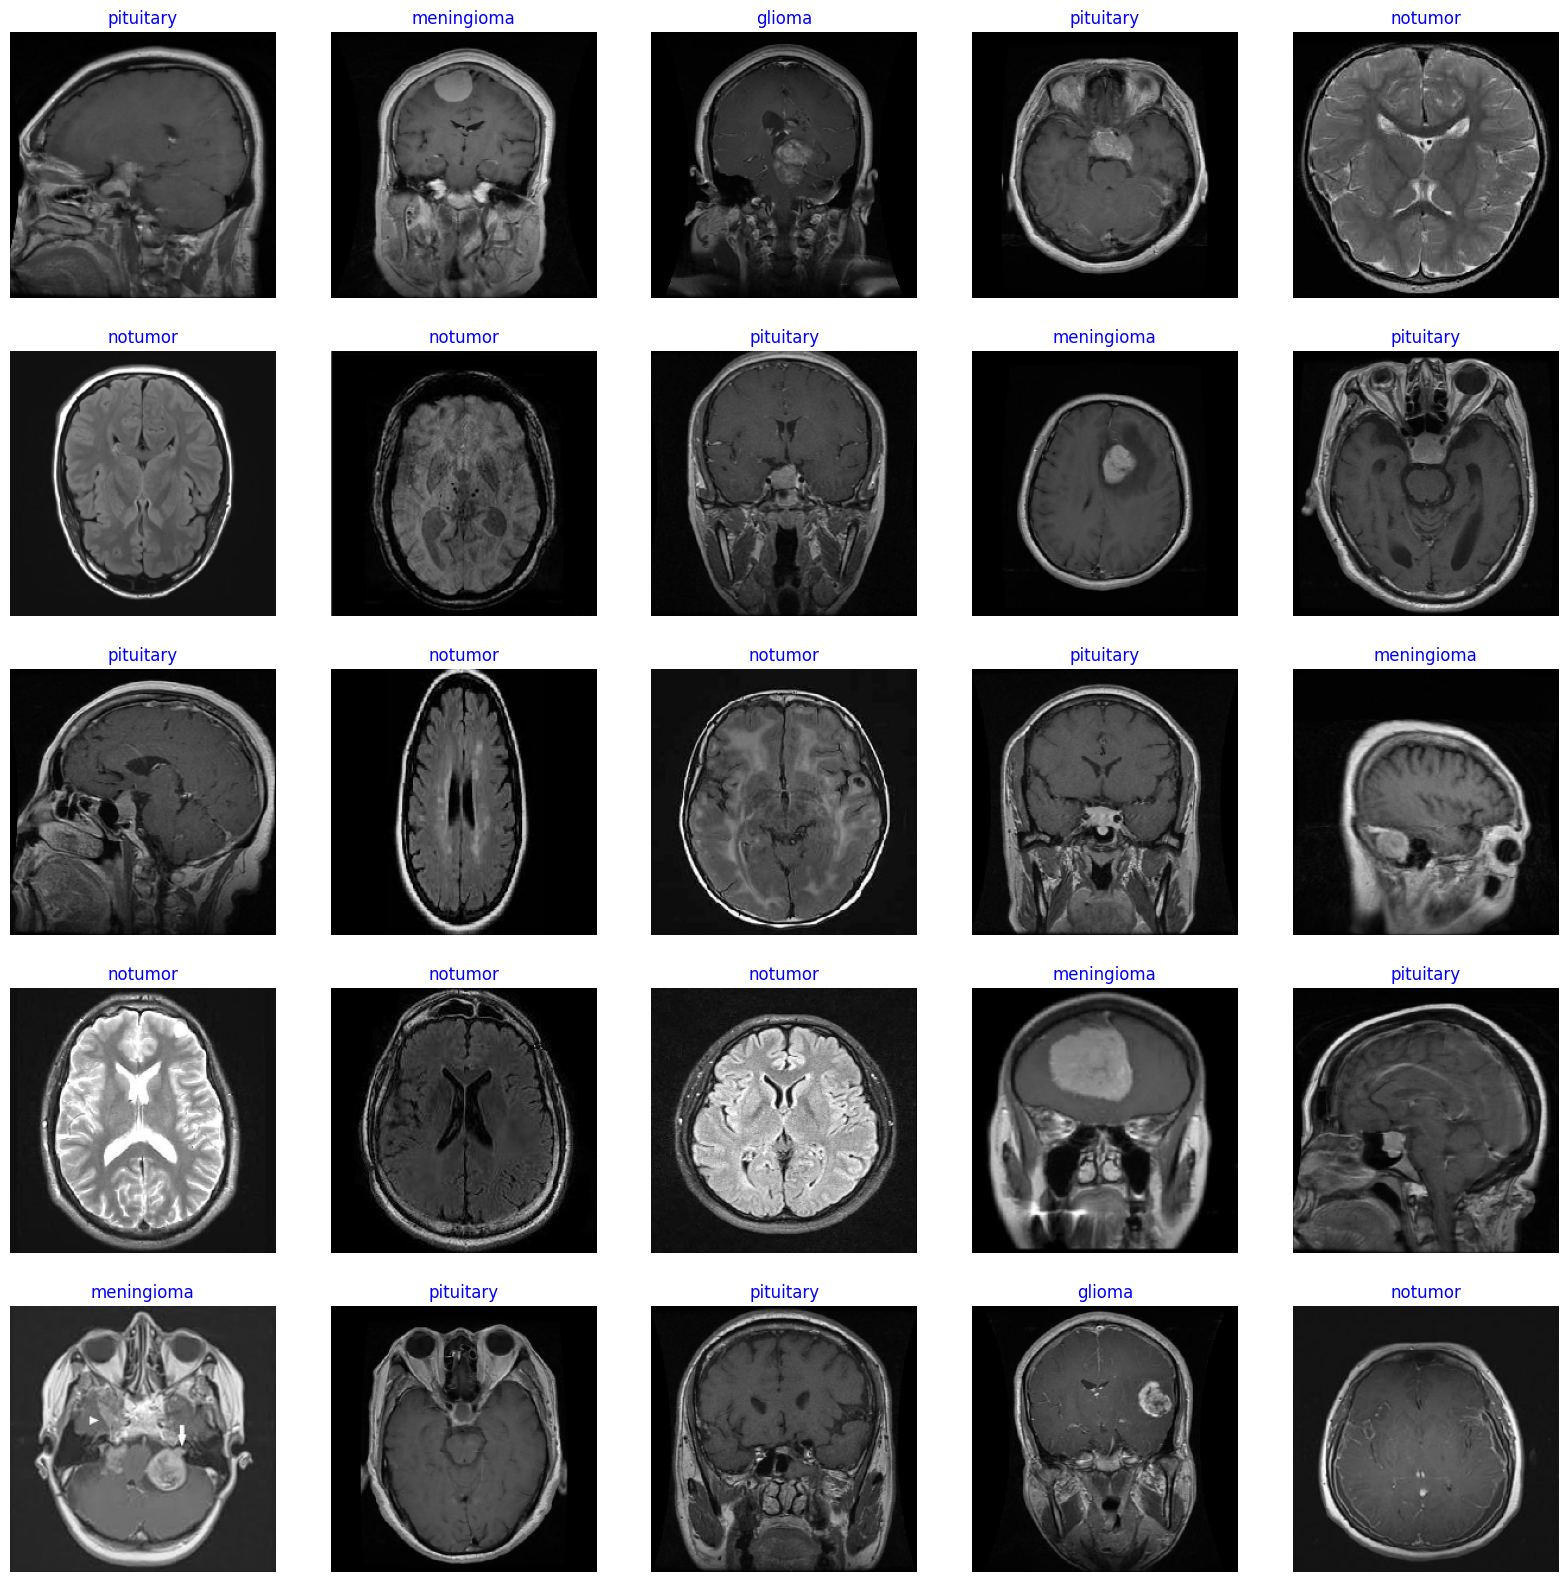

In [ ]:
# Get Dataframes
train_dir = '/content/drive/MyDrive/DataSet/Testing'
test_dir = '/content/drive/MyDrive/DataSet/Testing'
train_df, valid_df, test_df = split_data(train_dir, test_dir)

# Get Generators
batch_size = 40
train_gen, valid_gen, test_gen = create_model_data(train_df, valid_df, test_df, batch_size)

# Display Image Samples
show_images(train_gen)

#EDA

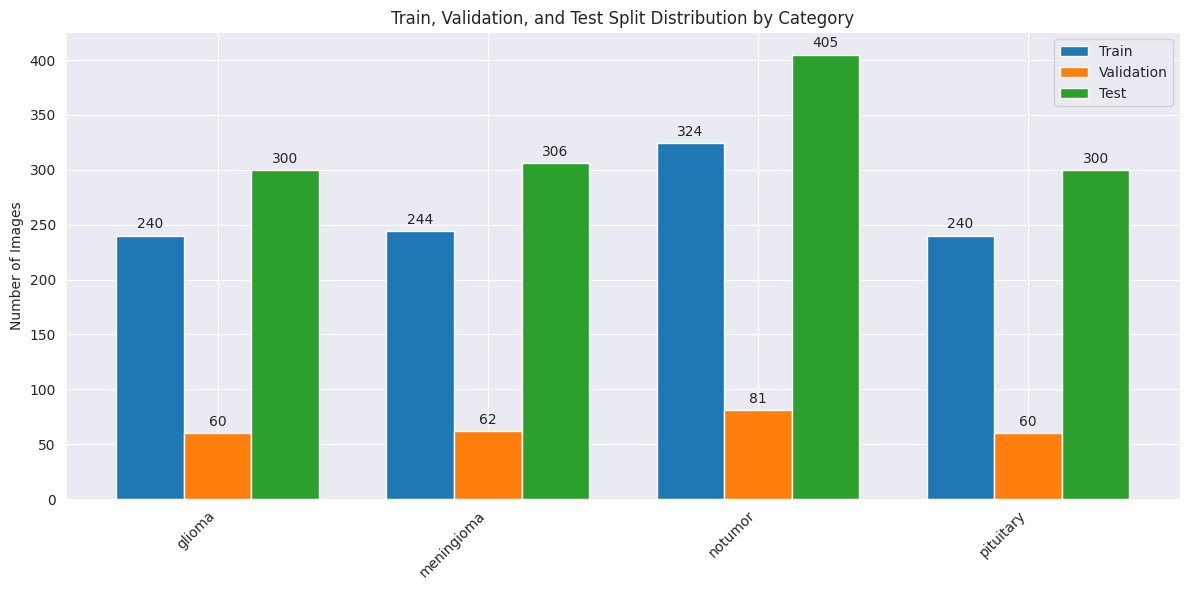

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_split_distribution(train_df, valid_df, test_df):
  """Plots the train, validation, and test split distribution for each category."""

  train_counts = train_df.groupby('labels').size()
  valid_counts = valid_df.groupby('labels').size()
  test_counts = test_df.groupby('labels').size()

  categories = train_counts.index.tolist()
  train_values = train_counts.values.tolist()
  valid_values = valid_counts.values.tolist()
  test_values = test_counts.values.tolist()

  x = np.arange(len(categories))  # the label locations
  width = 0.25  # the width of the bars

  fig, ax = plt.subplots(figsize=(12, 6))
  rects1 = ax.bar(x - width, train_values, width, label='Train')
  rects2 = ax.bar(x, valid_values, width, label='Validation')
  rects3 = ax.bar(x + width, test_values, width, label='Test')

  # Add some text for labels, title and custom x-axis tick labels, etc.
  ax.set_ylabel('Number of Images')
  ax.set_title('Train, Validation, and Test Split Distribution by Category')
  ax.set_xticks(x)
  ax.set_xticklabels(categories, rotation=45, ha='right')
  ax.legend()

  # Attach a text label above each bar in *rects*, displaying its height.
  def autolabel(rects):
      """Attach a text label above each bar in *rects*, displaying its height."""
      for rect in rects:
          height = rect.get_height()
          ax.annotate('{}'.format(height),
                      xy=(rect.get_x() + rect.get_width() / 2, height),
                      xytext=(0, 3),  # 3 points vertical offset
                      textcoords="offset points",
                      ha='center', va='bottom')

  autolabel(rects1)
  autolabel(rects2)
  autolabel(rects3)

  fig.tight_layout()
  plt.show()

# Assuming train_df, valid_df, and test_df are defined in your code
# Call the function to plot the distribution
plot_split_distribution(train_df, valid_df, test_df)


{'glioma': 352, 'meningioma': 367, 'notumor': 480, 'pituitary': 375}


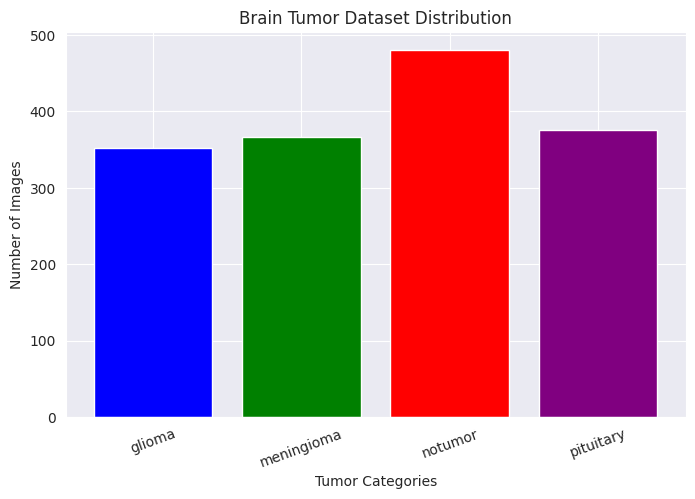

In [ ]:

import matplotlib.pyplot as plt

# Get the class indices from the training generator
class_labels = list(train_gen.class_indices.keys())

# Get the number of images in each category
train_counts = train_gen.classes
valid_counts = valid_gen.classes
test_counts = test_gen.classes

# Calculate total images per category
total_counts = {label: 0 for label in class_labels}
for label, count in zip(train_counts, valid_counts):
    total_counts[class_labels[label]] += 1
for label, count in zip(test_counts, test_counts):
    total_counts[class_labels[label]] += 1

print(total_counts)

# Plot the distribution
plt.figure(figsize=(8, 5))
plt.bar(total_counts.keys(), total_counts.values(), color=['blue', 'green', 'red', 'purple'])
plt.xlabel("Tumor Categories")
plt.ylabel("Number of Images")
plt.title("Brain Tumor Dataset Distribution")
plt.xticks(rotation=20)
plt.show()


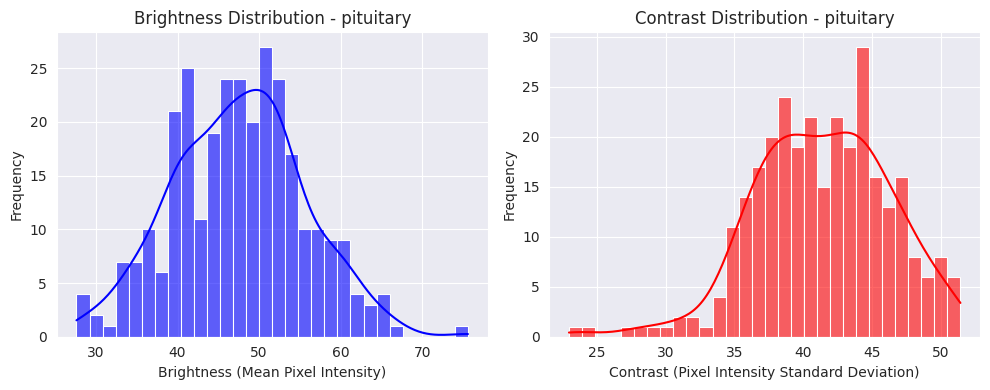

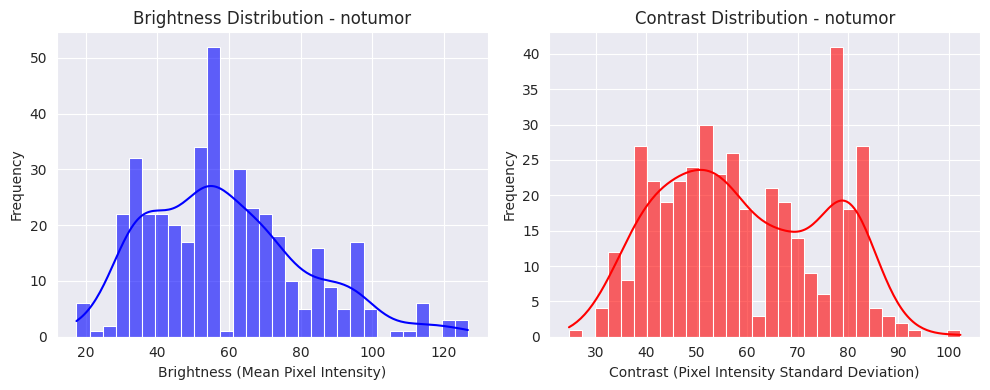

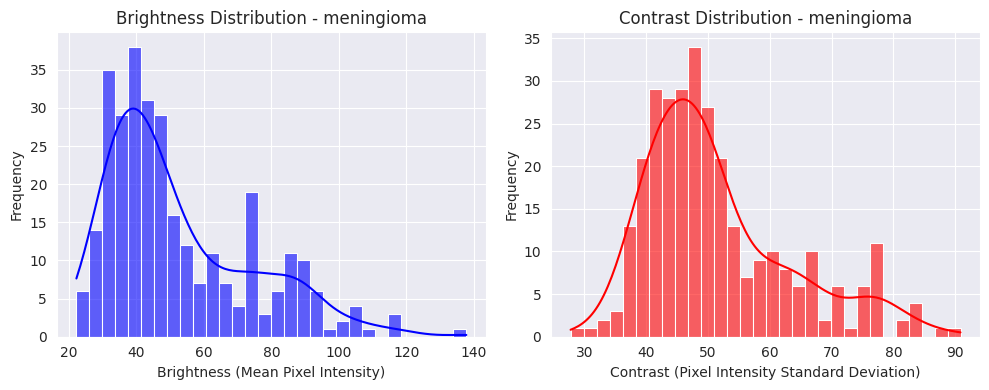

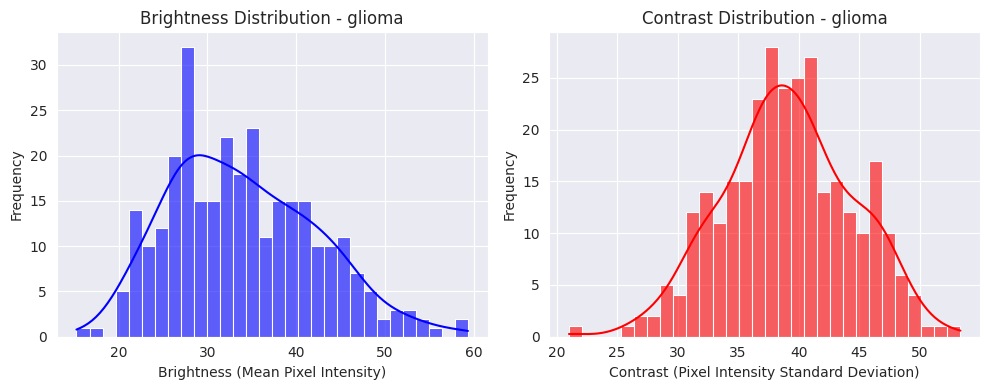

In [ ]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set dataset path
dataset_path = '/content/drive/MyDrive/DataSet/Testing'

# Initialize a dictionary to store brightness and contrast for each category
category_data = {}

# Function to compute brightness and contrast
def compute_brightness_contrast(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    brightness = np.mean(gray)  # Average pixel intensity
    contrast = np.std(gray)  # Standard deviation of intensity
    return brightness, contrast

# Iterate over each category
for category in os.listdir(dataset_path):
    category_path = os.path.join(dataset_path, category)
    if os.path.isdir(category_path):
        brightness_values = []
        contrast_values = []

        for img_name in os.listdir(category_path):
            img_path = os.path.join(category_path, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                brightness, contrast = compute_brightness_contrast(img)
                brightness_values.append(brightness)
                contrast_values.append(contrast)

        # Store data for each category
        category_data[category] = {'Brightness': brightness_values, 'Contrast': contrast_values}

# Plot histograms for each category separately
for category, values in category_data.items():
    plt.figure(figsize=(10, 4))

    # Brightness Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(values['Brightness'], bins=30, kde=True, color='blue', alpha=0.6)
    plt.title(f"Brightness Distribution - {category}")
    plt.xlabel("Brightness (Mean Pixel Intensity)")
    plt.ylabel("Frequency")

    # Contrast Histogram
    plt.subplot(1, 2, 2)
    sns.histplot(values['Contrast'], bins=30, kde=True, color='red', alpha=0.6)
    plt.title(f"Contrast Distribution - {category}")
    plt.xlabel("Contrast (Pixel Intensity Standard Deviation)")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()


#Baseline Modal


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam

# Input shape
input_shape = (224, 224, 3)
num_classes = len(train_gen.class_indices)

# Define a simple CNN architecture
baseline_model = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=input_shape),
    MaxPooling2D(pool_size=(2,2)),
    BatchNormalization(),

    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2,2)),
    BatchNormalization(),

    Conv2D(128, (3,3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2,2)),
    BatchNormalization(),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

# Compile
baseline_model.compile(optimizer=Adam(learning_rate=0.001),
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])

baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,844 (49.36 MB)

 Trainable params: 12,939,396 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Train baseline model
baseline_history = baseline_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=15,
    verbose=1
)


Epoch 1/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 25s 543ms/step - accuracy: 0.4644 - loss: 9.7335 - val_accuracy: 0.3080 - val_loss: 105.9434
Epoch 2/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 227ms/step - accuracy: 0.5209 - loss: 2.2403 - val_accuracy: 0.3118 - val_loss: 14.0093
Epoch 3/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 230ms/step - accuracy: 0.5190 - loss: 1.1984 - val_accuracy: 0.3802 - val_loss: 3.6010
Epoch 4/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 218ms/step - accuracy: 0.5479 - loss: 1.1048 - val_accuracy: 0.5475 - val_loss: 1.7460
Epoch 5/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 206ms/step - accuracy: 0.5798 - loss: 1.0636 - val_accuracy: 0.5323 - val_loss: 1.8124
Epoch 6/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 240ms/step - accuracy: 0.6230 - loss: 0.9583 - val_accuracy: 0.7376 - val_loss: 0.8698
Epoch 7/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 220ms/step - accuracy: 0.5882 - loss: 0.8949 - val_accuracy: 0.6730 - val_loss: 0.8598
Epoch 8/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 236ms/step - accuracy: 0.5824 - loss: 0.8903 - val_accurac

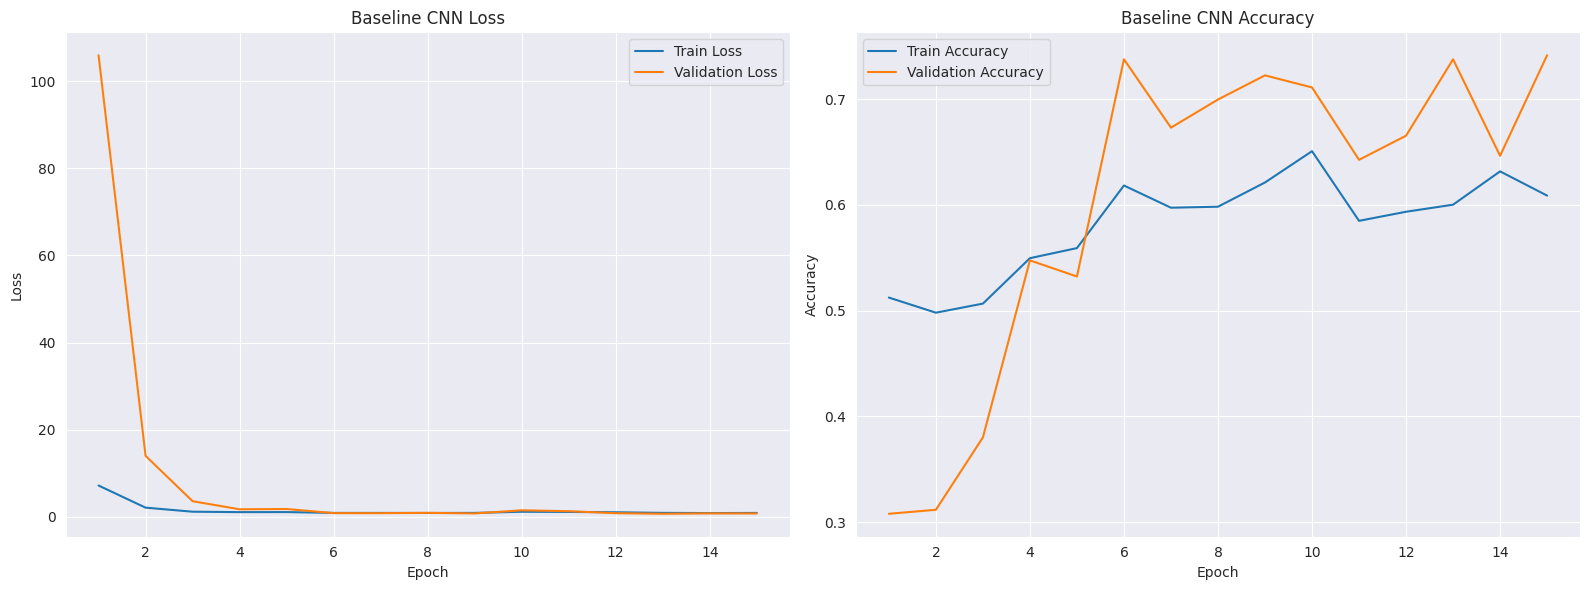

In [ ]:
def plot_training_baseline(history, model_name='Baseline CNN'):
    tr_acc = history.history['accuracy']
    tr_loss = history.history['loss']
    val_acc = history.history['val_accuracy']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(tr_acc)+1)

    plt.figure(figsize=(16,6))
    plt.subplot(1,2,1)
    plt.plot(epochs_range, tr_loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.title('Baseline CNN Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs_range, tr_acc, label='Train Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.title('Baseline CNN Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Plot
plot_training_baseline(baseline_history)


In [ ]:
# Evaluate baseline model on test set
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(test_gen, verbose=1)
print(f"Baseline CNN - Test Accuracy: {baseline_test_acc * 100:.2f}%")
print(f"Baseline CNN - Test Loss: {baseline_test_loss:.4f}")


19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 558ms/step - accuracy: 0.9027 - loss: 0.6051
Baseline CNN - Test Accuracy: 79.94%
Baseline CNN - Test Loss: 0.6641


19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 348ms/step


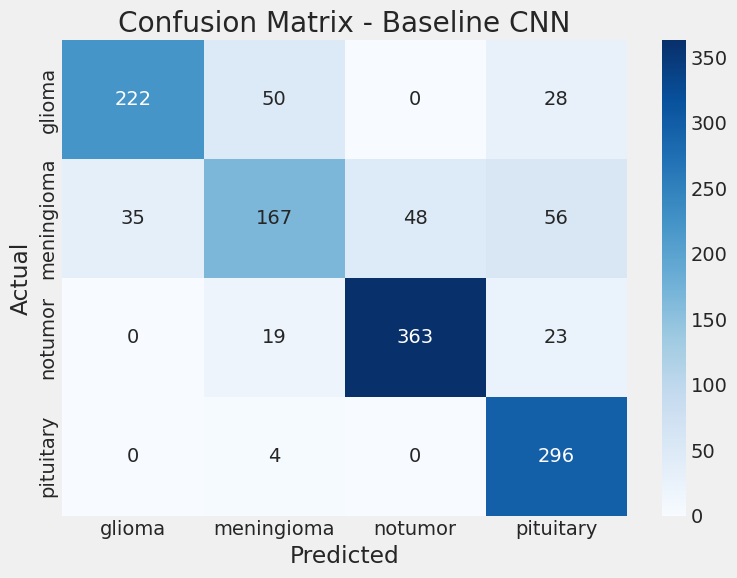


Classification Report - Baseline CNN

              precision    recall  f1-score   support

      glioma       0.86      0.74      0.80       300
  meningioma       0.70      0.55      0.61       306
     notumor       0.88      0.90      0.89       405
   pituitary       0.73      0.99      0.84       300

    accuracy                           0.80      1311
   macro avg       0.79      0.79      0.79      1311
weighted avg       0.80      0.80      0.79      1311



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Get predictions from baseline model
baseline_preds = baseline_model.predict(test_gen, verbose=1)
baseline_pred_classes = np.argmax(baseline_preds, axis=1)

# True labels
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(true_classes, baseline_pred_classes)

# Plot
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix - Baseline CNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Print classification report
print("\nClassification Report - Baseline CNN\n")
print(classification_report(true_classes, baseline_pred_classes, target_names=class_labels))


# Final Model - EfficientNetB3


In [ ]:
from tensorflow.keras.applications.efficientnet import EfficientNetB3, preprocess_input

# Set shape
img_size = (224, 224)
img_shape = (img_size[0], img_size[1], 3)
class_count = len(train_gen.class_indices)

# Load EfficientNet with pretrained weights
base_model = EfficientNetB3(include_top=False, weights='imagenet', input_shape=img_shape, pooling='max')

# Unfreeze upper layers for fine-tuning
base_model.trainable = True
for layer in base_model.layers[:300]:  # Freeze first 300 layers
    layer.trainable = False

# Define full model
model = Sequential([
    base_model,
    BatchNormalization(),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    Dropout(0.4),
    Dense(class_count, activation='softmax')
])

model.compile(optimizer=Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb3 (Functional)     │ (None, 1536)           │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,184,179 (42.66 MB)

 Trainable params: 7,309,942 (27.89 MB)

 Non-trainable params: 3,874,237 (14.78 MB)

#### Set Callback Parameters

In [ ]:

from sklearn.utils.class_weight import compute_class_weight

# Get label classes from dataframe
labels = train_df['labels']
unique_classes = np.unique(labels)
weights = compute_class_weight(class_weight='balanced', classes=unique_classes, y=labels)
class_weights = dict(zip(train_gen.class_indices.values(), weights))

# Training config
batch_size = 40
epochs = 20
patience = 2
stop_patience = 6
threshold = 0.5
factor = 0.7
ask_epoch = 5
batches = int(np.ceil(len(train_gen.labels) / batch_size))

callbacks = [MyCallback(
    monitor='val_loss',
    min_delta=0.001,
    warmup=3,
    patience=patience,
    stop_patience=stop_patience,
    factor=factor,
    epochs=epochs,
    ask_epoch=ask_epoch
)]




#### Train model

In [ ]:
history = model.fit(
    x=train_gen,
    validation_data=valid_gen,
    epochs=epochs,
    callbacks=callbacks,
    class_weight=class_weights,
    shuffle=False,
    verbose=0
)


Epoch   Loss      Accuracy  V_loss    V_acc     LR        Next LR   % Improv  Duration  
 1/20   5.177     70.134    8.595     43.726    0.001000  0.001000  0.00      119.14    
 2/20   4.339     89.313    5.003     70.722    0.001000  0.001000  0.00      7.62      
 3/20   3.949     93.511    4.284     84.030    0.001000  0.001000  0.00      6.21      
 4/20   3.703     95.134    3.814     90.494    0.001000  0.001000  0.00      6.76      
 5/20   3.455     97.615    3.597     90.494    0.001000  0.001000  5.69      6.09      

Do you want model to ask you to halt training [y/n]?
n
 6/20   3.249     97.615    3.369     90.494    0.001000  0.001000  6.35      142.36    
 7/20   3.083     97.424    3.214     90.494    0.001000  0.001000  4.60      6.52      
 8/20   2.909     97.519    3.072     92.776    0.001000  0.001000  4.40      6.67      
 9/20   2.710     98.473    2.841     91.255    0.001000  0.001000  7.53      7.90      
10/20   2.559     98.664    2.706     90.875    0.0010

#### Display model performance

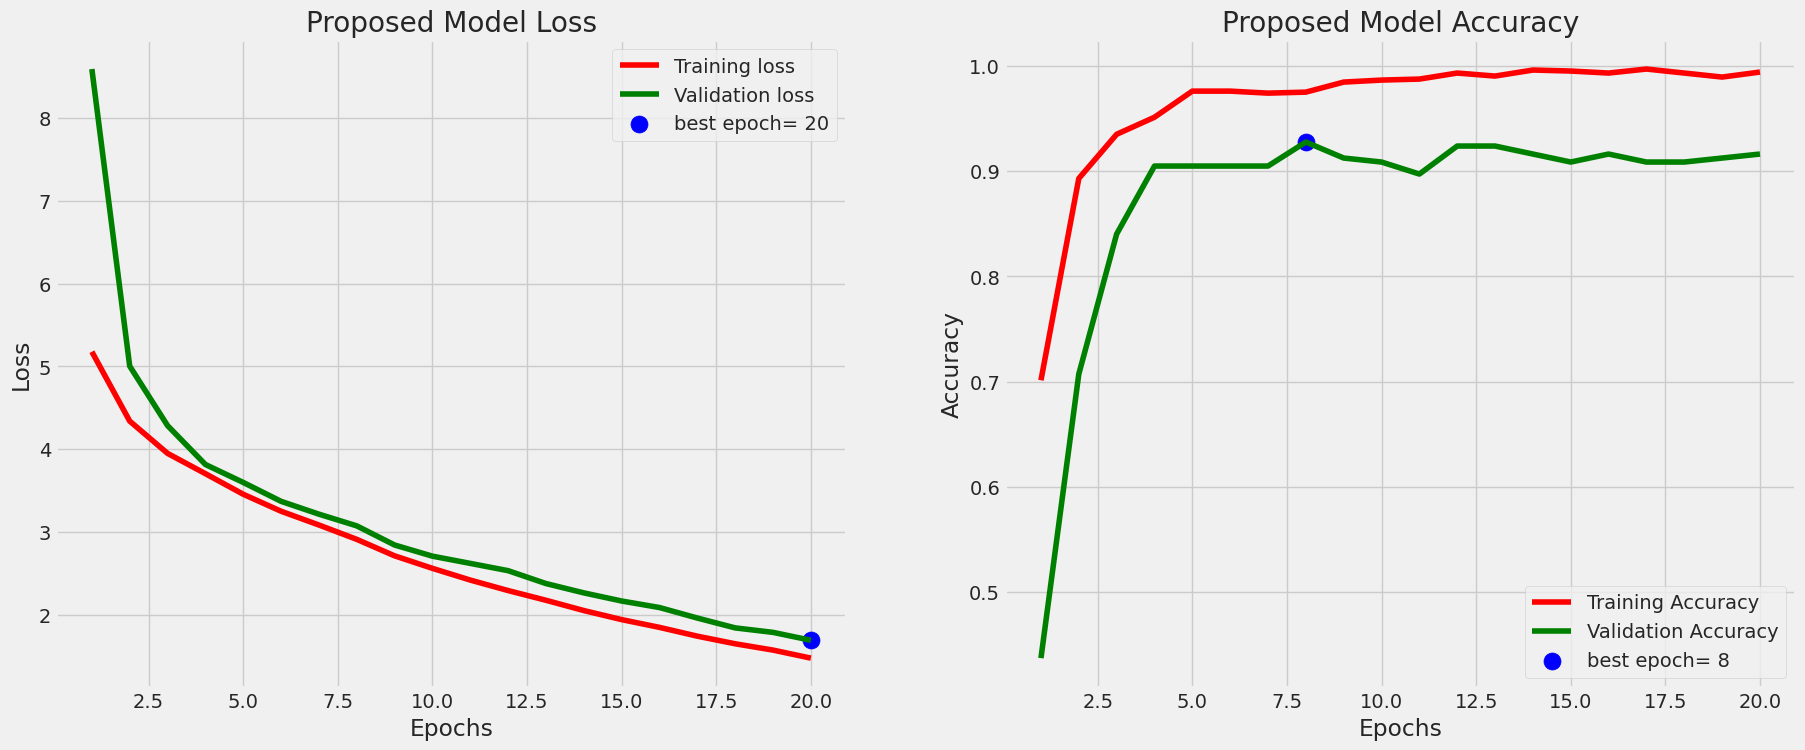

In [ ]:
plot_training(history)

### Evaluate model

In [ ]:
ts_length = len(test_df)
test_batch_size = test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

train_score = model.evaluate(train_gen, steps= test_steps, verbose= 1)
valid_score = model.evaluate(valid_gen, steps= test_steps, verbose= 1)
test_score = model.evaluate(test_gen, steps= test_steps, verbose= 1)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 372ms/step - accuracy: 0.9981 - loss: 1.4173
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9169 - loss: 1.6771 
19/19 ━━━━━━━━━━━━━━━━━━━━ 17s 331ms/step - accuracy: 0.9871 - loss: 1.4550
Train Loss:  1.4157873392105103
Train Accuracy:  0.9986842274665833
--------------------
Validation Loss:  1.6893080472946167
Validation Accuracy:  0.9163498282432556
--------------------
Test Loss:  1.470223069190979
Test Accuracy:  0.9824561476707458


### Get Predictions

In [ ]:
preds = model.predict(test_gen)
y_pred = np.argmax(preds, axis=1)
print(y_pred)

19/19 ━━━━━━━━━━━━━━━━━━━━ 16s 357ms/step
[3 3 3 ... 0 0 0]


#### Confusion Matrics and Classification Report

Confusion Matrix, Without Normalization
[[294   6   0   0]
 [  4 295   1   6]
 [  0   4 401   0]
 [  2   0   0 298]]
              precision    recall  f1-score   support

      glioma       0.98      0.98      0.98       300
  meningioma       0.97      0.96      0.97       306
     notumor       1.00      0.99      0.99       405
   pituitary       0.98      0.99      0.99       300

    accuracy                           0.98      1311
   macro avg       0.98      0.98      0.98      1311
weighted avg       0.98      0.98      0.98      1311



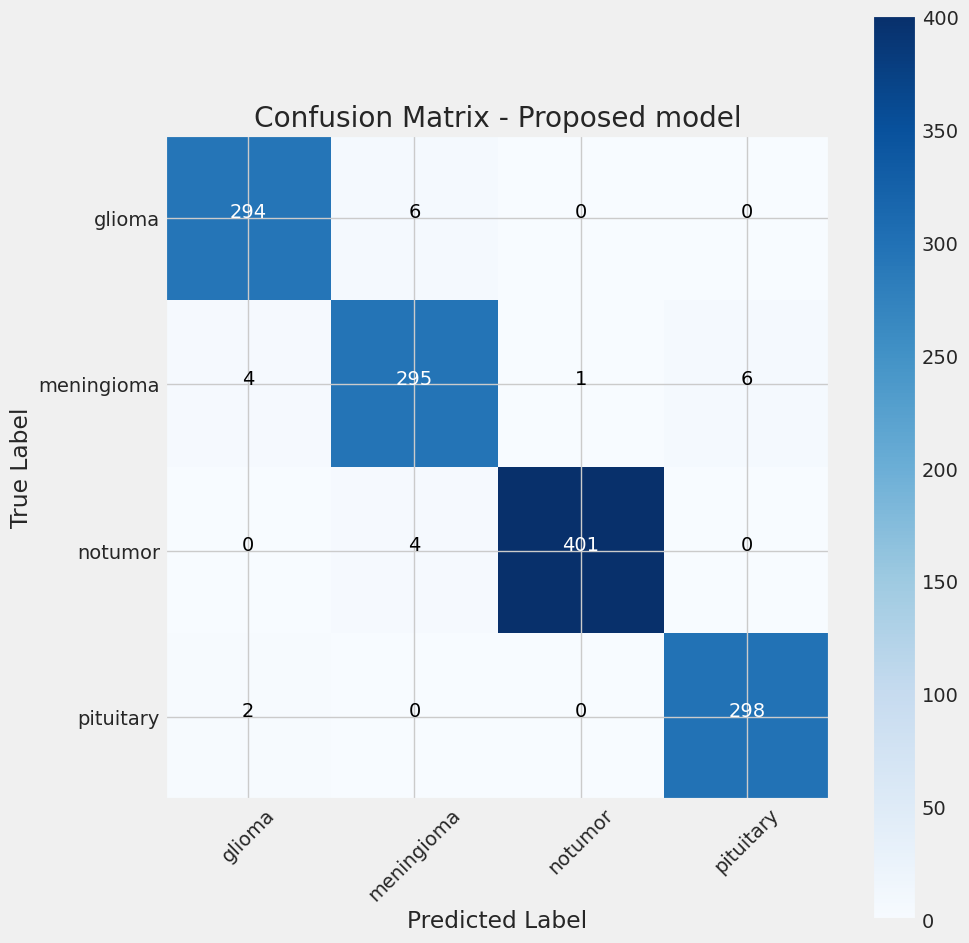

In [ ]:
g_dict = test_gen.class_indices
classes = list(g_dict.keys())

# Confusion matrix
cm = confusion_matrix(test_gen.classes, y_pred)
plot_confusion_matrix(cm= cm, classes= classes, title = 'Confusion Matrix - Proposed model')

# Classification report
print(classification_report(test_gen.classes, y_pred, target_names= classes))

### Save model

In [ ]:
model_name = 'EfficientNetB3'
subject = input('Enter Project Subject: ')
acc = test_score[1] * 100
save_path = ''  # or specify path like '/content/drive/MyDrive/models'

# Save model (still works but legacy format)
save_id = f'{model_name}-{subject}-{"%.2f" % round(acc, 2)}.h5'
model_save_loc = os.path.join(save_path, save_id)
model.save(model_save_loc)
print(f'Model was saved as {model_save_loc}')

# Save weights with proper extension
weight_save_id = f'{model_name}-{subject}.weights.h5'
weights_save_loc = os.path.join(save_path, weight_save_id)
model.save_weights(weights_save_loc)
print(f'Weights were saved as {weights_save_loc}')


Enter Project Subject: Brain-Tumor-Detection-Final


Model was saved as EfficientNetB3-Brain-Tumor-Detection-Final-98.32.h5
Weights were saved as EfficientNetB3-Brain-Tumor-Detection-Final.weights.h5


### Generate CSV files containing classes indicies & image size

In [ ]:
class_dict = train_gen.class_indices
img_size = train_gen.image_shape
height = []
width = []
for _ in range(len(class_dict)):
    height.append(img_size[0])
    width.append(img_size[1])

Index_series = pd.Series(list(class_dict.values()), name= 'class_index')
Class_series = pd.Series(list(class_dict.keys()), name= 'class')
Height_series = pd.Series(height, name= 'height')
Width_series = pd.Series(width, name= 'width')
class_df = pd.concat([Index_series, Class_series, Height_series, Width_series], axis= 1)
csv_name = f'{subject}-class_dict.csv'
csv_save_loc = os.path.join(save_path, csv_name)
class_df.to_csv(csv_save_loc, index= False)
print(f'class csv file was saved as {csv_save_loc}')

class csv file was saved as Brain-Tumor-Detection-Final-class_dict.csv


# Thank You